# 1. What an asymptotic expansion is

**Track:** core &nbsp;·&nbsp; **Prerequisites:** calculus, Taylor series

A physicist who meets an integral that cannot be done, or an equation that cannot
be solved, usually looks for a small parameter and expands in it. The result is
often a series that *diverges*: its terms eventually grow without bound, whatever
the value of the parameter. Such a series is nevertheless one of the most accurate
and economical approximations available, provided it is used correctly. This
chapter shows, on two examples, what such a series is, how accurate it is, and
how to tell. The same check, the error measured against an accurate numerical
value and plotted on logarithmic axes, is applied to every result in this book.

In [1]:
import math

import matplotlib.pyplot as plt
import mpmath as mp
import numpy as np

try:
    import asymp as am
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import asymp as am

am.use_style()
mp.mp.dps = 40               # 40 significant digits for the reference values

## 1.1 A divergent series that works

Consider the integral

$$ E(x) = \int_0^\infty \frac{e^{-t}}{1 + x t}\,\mathrm dt , \qquad x > 0 , $$

which appears, for example, in the theory of the Stieltjes transform and of
radiative transfer. For small $x$ the factor $1/(1 + xt)$ is close to 1 wherever
$e^{-t}$ is not negligible, so we expand it in powers of $xt$,

$$ \frac{1}{1 + xt} = 1 - xt + x^2t^2 - x^3t^3 + \dots , $$

and integrate term by term with $\int_0^\infty t^n e^{-t}\,\mathrm dt = n!$:

$$ E(x) \sim 1 - x + 2!\,x^2 - 3!\,x^3 + \dots = \sum_{n=0}^{\infty} (-1)^n\,n!\,x^n . $$

The step is not legitimate: the geometric series converges only for $xt < 1$,
while the integral runs to $t = \infty$. And the result shows it: the ratio of
successive terms is $n x$, which exceeds 1 as soon as $n > 1/x$. The series
diverges for every $x > 0$. Euler, who studied it in 1760, nonetheless used it
to compute $E(x)$, and he was right to.

The exact value is available in closed form, $E(x) = x^{-1} e^{1/x} E_1(1/x)$, with
$E_1$ the exponential integral, which mpmath evaluates to any precision. The cell
compares the partial sums with it.

In [2]:
def euler_exact(x):
    x = mp.mpf(x)
    return mp.e ** (1 / x) / x * mp.e1(1 / x)


def euler_terms(x, n_max):
    """Terms (-1)^n n! x^n, n = 0 .. n_max - 1, computed by recursion."""
    terms = np.empty(n_max)
    t = 1.0
    for n in range(n_max):
        terms[n] = t
        t *= -(n + 1) * x
    return terms


for x in (0.05, 0.1, 0.2):
    exact = float(euler_exact(x))
    s = am.partial_sums(euler_terms(x, 60))
    err = np.abs(s - exact)
    best = int(np.argmin(err))
    print(f"x = {x:4.2f}:  E(x) = {exact:.15f}")
    print(f"          error with 1, 2, 3 terms: {err[0]:.1e}, {err[1]:.1e}, {err[2]:.1e}")
    print(f"          smallest error {err[best]:.2e} with {best + 1} terms;"
          f"  with 40 terms: {err[39]:.1e}")

x = 0.05:  E(x) = 0.954370909919217
          error with 1, 2, 3 terms: 4.6e-02, 4.4e-03, 6.3e-04
          smallest error 1.15e-08 with 20 terms;  with 40 terms: 2.5e-05
x = 0.10:  E(x) = 0.915633339397881
          error with 1, 2, 3 terms: 8.4e-02, 1.6e-02, 4.4e-03
          smallest error 1.77e-04 with 10 terms;  with 40 terms: 1.6e+07
x = 0.20:  E(x) = 0.852110881423661
          error with 1, 2, 3 terms: 1.5e-01, 5.2e-02, 2.8e-02
          smallest error 1.83e-02 with 5 terms;  with 40 terms: 9.9e+18


For $x = 0.1$, the first three terms give $E$ to better than 1 %, and ten terms
give it to about four digits. After that, adding terms makes the result *worse*,
and with 40 terms it is worse by many orders of magnitude. For smaller $x$ the
series is useful for longer and becomes more accurate. A convergent series behaves
in the opposite way: the more terms, the better, for a fixed $x$.

## 1.2 How accurate can it be? Optimal truncation

The natural strategy is to stop just before the smallest term, the rule of
**optimal truncation**. The smallest term is the one with $n \approx 1/x$. Its
size follows from Stirling's formula $n! \approx \sqrt{2\pi n}\,(n/e)^n$
(Chapter 9): with $n = 1/x$,

$$ n!\,x^n \approx \sqrt{\frac{2\pi}{x}}\;e^{-1/x} . $$

The error itself can be written exactly. Stopping after $N$ terms leaves the
remainder

$$ R_N(x) = (-x)^N \int_0^\infty \frac{t^N e^{-t}}{1 + xt}\,\mathrm dt , $$

as one checks by summing the geometric series with its remainder,
$1/(1+y) = \sum_{n<N} (-y)^n + (-y)^N/(1+y)$. For $N \approx 1/x$, the factor
$t^N e^{-t}$ is sharply peaked at $t = N$, where $1/(1 + xt) \approx 1/2$, so

$$ |R_N| \approx \tfrac12\,N!\,x^N \approx \sqrt{\frac{\pi}{2x}}\;e^{-1/x} . $$

The error of the optimally truncated series is therefore **exponentially small**:
smaller than any power of $x$. This is the general picture for the divergent
series of physics, studied in Chapter 4.

In [3]:
xs_opt = np.array([0.03, 0.04, 0.05, 0.07, 0.1, 0.14, 0.2, 0.3])
opt_err, opt_pred = [], []
for x in xs_opt:
    tr = am.optimal_truncation(euler_terms(x, 200))
    opt_err.append(abs(tr.value - float(euler_exact(x))))
    opt_pred.append(math.sqrt(math.pi / (2 * x)) * math.exp(-1 / x))
    print(f"x = {x:4.2f}: keep {tr.n_terms:2d} terms, error {opt_err[-1]:.3e},"
          f"  sqrt(pi/2x) exp(-1/x) = {opt_pred[-1]:.3e},  smallest term {tr.smallest:.3e}")

x = 0.03: keep 33 terms, error 2.387e-14,  sqrt(pi/2x) exp(-1/x) = 2.416e-14,  smallest term 4.827e-14
x = 0.04: keep 24 terms, error 8.818e-11,  sqrt(pi/2x) exp(-1/x) = 8.703e-11,  smallest term 1.746e-10
x = 0.05: keep 19 terms, error 1.174e-08,  sqrt(pi/2x) exp(-1/x) = 1.155e-08,  smallest term 2.320e-08
x = 0.07: keep 14 terms, error 2.934e-06,  sqrt(pi/2x) exp(-1/x) = 2.960e-06,  smallest term 5.913e-06
x = 0.10: keep  9 terms, error 1.859e-04,  sqrt(pi/2x) exp(-1/x) = 1.799e-04,  smallest term 3.629e-04
x = 0.14: keep  7 terms, error 2.591e-03,  sqrt(pi/2x) exp(-1/x) = 2.648e-03,  smallest term 5.313e-03
x = 0.20: keep  4 terms, error 2.011e-02,  sqrt(pi/2x) exp(-1/x) = 1.888e-02,  smallest term 3.840e-02
x = 0.30: keep  3 terms, error 7.881e-02,  sqrt(pi/2x) exp(-1/x) = 8.163e-02,  smallest term 1.620e-01


The prediction matches the actual error to within 7 %, and the smallest term
is about twice the error, as the factor $\tfrac12$ says. At $x = 0.03$ the
truncated series gives thirteen correct digits.

## 1.3 The definition: fixed number of terms, small parameter

What, then, does the series mean, if not that its sum equals $E(x)$? Poincaré's
answer (1886) defines an asymptotic series by what happens as the parameter goes
to zero with the number of terms *fixed*:

$$ f(x) \sim \sum_{n=0}^{\infty} a_n x^n \quad (x \to 0)
   \quad\text{means}\quad
   f(x) - \sum_{n=0}^{N-1} a_n x^n = O\!\left(x^N\right) \quad\text{for every } N . $$

A convergent series makes a statement about $N \to \infty$ at fixed $x$; an
asymptotic series makes a statement about $x \to 0$ at fixed $N$. The two are
different questions, and a series can satisfy the second without the first.

The definition gives a practical test that is used throughout the book. If the
error after $N$ terms is of order $x^N$, then on a log-log plot of the error
against $x$ it is a straight line of slope $N$. The function `am.loglog_slope`
measures that slope over a chosen range of $x$.

In [4]:
xs = np.logspace(-3, -0.5, 26)
exact_xs = np.array([float(euler_exact(x)) for x in xs])
err_N = {}
for N in (1, 2, 3, 4):
    err_N[N] = np.abs(np.array([euler_terms(x, N).sum() for x in xs]) - exact_xs)
    slope, pref = am.loglog_slope(xs, err_N[N], fit_range=(1e-3, 1e-2))
    print(f"N = {N} terms: error ~ {pref:.2f} x^{slope:.3f}   (expected: {math.factorial(N)} x^{N})")

N = 1 terms: error ~ 0.95 x^0.993   (expected: 1 x^1)
N = 2 terms: error ~ 1.86 x^1.989   (expected: 2 x^2)
N = 3 terms: error ~ 5.44 x^2.986   (expected: 6 x^3)
N = 4 terms: error ~ 21.23 x^3.982   (expected: 24 x^4)


The measured slopes are $N$ to within 0.02, and the prefactors are close to
$N!$, the coefficient of the first omitted term (slightly below it, because the
next term has the opposite sign). This is the meaning of an asymptotic
expansion, and it is what each later chapter verifies for its own results: an
expansion is checked by the slope of its error, not merely by its value at one
point.

## 1.4 Convergent is not the same as useful

The opposite lesson is just as important: a convergent series can be useless. The
complementary error function, which describes diffusion from a boundary
(Chapter 11), has a Taylor series that converges for every $x$,

$$ \operatorname{erfc} x = 1 - \frac{2}{\sqrt\pi}\sum_{n=0}^{\infty} \frac{(-1)^n x^{2n+1}}{n!\,(2n+1)} , $$

and an asymptotic series for large $x$ (derived in Chapter 5) that diverges for
every $x$,

$$ \operatorname{erfc} x \sim \frac{e^{-x^2}}{x\sqrt\pi}\left(1 - \frac{1}{2x^2}
   + \frac{1\cdot 3}{(2x^2)^2} - \frac{1\cdot 3\cdot 5}{(2x^2)^3} + \dots\right) . $$

The cell evaluates both in ordinary double precision and compares them with the
exact value.

In [5]:
def erfc_taylor(x, n_terms):
    """Partial sums of 1 - erf from the Taylor series, in double precision."""
    out, s, a = [], 0.0, x
    for n in range(n_terms):
        s += 2 / math.sqrt(math.pi) * a / (2 * n + 1)
        out.append(1.0 - s)
        a *= -x * x / (n + 1)
    return np.array(out)


def erfc_asymptotic(x, n_terms):
    out, s, t = [], 0.0, 1.0
    for n in range(n_terms):
        if n > 0:
            t *= -(2 * n - 1) / (2 * x * x)
        s += t
        out.append(math.exp(-x * x) / (x * math.sqrt(math.pi)) * s)
    return np.array(out)


x_cmp = np.linspace(1.0, 5.5, 19)
best_taylor, best_asym = [], []
for x in x_cmp:
    exact = float(mp.erfc(x))
    best_taylor.append(np.min(np.abs(erfc_taylor(x, 250) - exact)) / exact)
    best_asym.append(np.min(np.abs(erfc_asymptotic(x, 60) - exact)) / exact)
best_taylor, best_asym = np.array(best_taylor), np.array(best_asym)
for x in (2.0, 3.0, 4.0, 5.0):
    i = np.argmin(np.abs(x_cmp - x))
    exact = float(mp.erfc(x))
    three = abs(erfc_asymptotic(x, 3)[-1] - exact) / exact
    print(f"x = {x}: erfc = {exact:.3e};  best relative error, Taylor: {best_taylor[i]:.1e};"
          f"  asymptotic: {best_asym[i]:.1e}  (3 terms: {three:.1e})")

x = 2.0: erfc = 4.678e-03;  best relative error, Taylor: 7.6e-14;  asymptotic: 1.4e-02  (3 terms: 1.8e-02)
x = 3.0: erfc = 2.209e-05;  best relative error, Taylor: 1.1e-09;  asymptotic: 9.1e-05  (3 terms: 2.0e-03)
x = 4.0: erfc = 1.542e-08;  best relative error, Taylor: 9.3e-04;  asymptotic: 8.2e-08  (3 terms: 3.9e-04)
x = 5.0: erfc = 1.537e-12;  best relative error, Taylor: 8.5e+03;  asymptotic: 1.0e-11  (3 terms: 1.1e-04)


At $x = 2$ the convergent series wins easily. By $x = 4$ it has lost most of its
digits, and at $x = 5$ it gives no correct digit at all, although it converges.
The reason is cancellation: the terms of the Taylor series grow to about
$10^9$ at $x = 5$ before they decrease, and they must cancel to leave
$1 - \operatorname{erf} x \approx 10^{-12}$. Double precision keeps 16 digits, so
nothing survives (Section 19.2 of the companion book
[*Error analysis and propagation*](https://github.com/ktwyw/error-analysis) treats
cancellation in detail). The divergent asymptotic series has no such problem:
three terms give four digits, and optimal truncation gives eleven. The two series
answer different questions, and each is good where the other is poor.

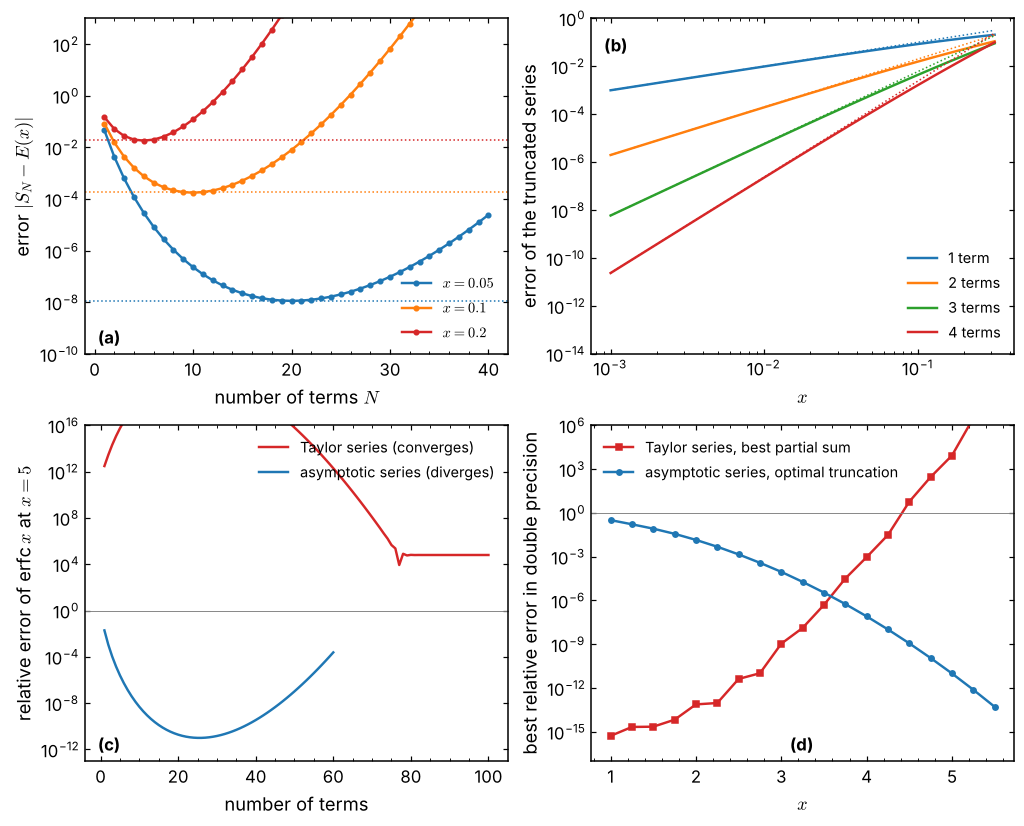

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.4))

ax = axes[0, 0]
for x, c in ((0.05, "C0"), (0.1, "C1"), (0.2, "C3")):
    n = np.arange(1, 41)
    err = np.abs(am.partial_sums(euler_terms(x, 40)) - float(euler_exact(x)))
    ax.semilogy(n, err, "o-", ms=3, color=c, label=f"$x = {x}$")
    ax.axhline(math.sqrt(math.pi / (2 * x)) * math.exp(-1 / x), color=c, ls=":", lw=1)
ax.set_xlabel("number of terms $N$"); ax.set_ylabel(r"error $|S_N - E(x)|$")
ax.set_ylim(1e-10, 1e3); ax.legend(loc="lower right"); am.panel_label(ax, "(a)", y=0.08)

ax = axes[0, 1]
for N, c in zip((1, 2, 3, 4), ("C0", "C1", "C2", "C3")):
    ax.loglog(xs, err_N[N], color=c, label=f"{N} term" + ("s" if N > 1 else ""))
    ax.loglog(xs, math.factorial(N) * xs**N, ":", color=c, lw=1)
ax.set_xlabel("$x$"); ax.set_ylabel("error of the truncated series")
ax.set_ylim(1e-14, 1); ax.legend(loc="lower right"); am.panel_label(ax, "(b)")

ax = axes[1, 0]
x5 = 5.0
exact5 = float(mp.erfc(x5))
ax.semilogy(np.arange(1, 101), np.abs(erfc_taylor(x5, 100) - exact5) / exact5, "C3", label="Taylor series (converges)")
ax.semilogy(np.arange(1, 61), np.abs(erfc_asymptotic(x5, 60) - exact5) / exact5, "C0", label="asymptotic series (diverges)")
ax.axhline(1, color="0.5", lw=0.6)
ax.set_xlabel("number of terms"); ax.set_ylabel(r"relative error of erfc$\,x$ at $x = 5$")
ax.set_ylim(1e-13, 1e16); ax.legend(loc="upper right"); am.panel_label(ax, "(c)", y=0.08)

ax = axes[1, 1]
ax.semilogy(x_cmp, best_taylor, "s-", ms=3.5, color="C3", label="Taylor series, best partial sum")
ax.semilogy(x_cmp, best_asym, "o-", ms=3.5, color="C0", label="asymptotic series, optimal truncation")
ax.axhline(1, color="0.5", lw=0.6)
ax.set_xlabel("$x$"); ax.set_ylabel("best relative error in double precision")
ax.set_ylim(1e-17, 1e6); ax.legend(loc="upper left"); am.panel_label(ax, "(d)", x=0.47, y=0.08)
plt.show()

**(a)** Error of the partial sums of Euler's series against the number of terms;
dotted lines: the predicted error at optimal truncation,
$\sqrt{\pi/2x}\,e^{-1/x}$. **(b)** Error with a fixed number of terms against $x$;
dotted lines: the first omitted term $N!\,x^N$. **(c)** The two series for
$\operatorname{erfc} 5$, term by term, in double precision. **(d)** The best
accuracy each series can reach, against $x$.

## Summary

* An asymptotic series is defined by its behaviour as the parameter goes to zero
  with the number of terms fixed: the error after $N$ terms is of the order of the
  first omitted term.
* Most series of applied mathematics diverge. Truncated near their smallest term,
  they are nonetheless extremely accurate, with an error that is often
  exponentially small.
* A convergent series is not necessarily useful: it may need very many terms, or
  lose all its digits to cancellation.
* The test used throughout this book: compute the error against an accurate
  reference and check that its log-log slope is the predicted order.

## Suggested references

* C. M. Bender and S. A. Orszag, *Advanced Mathematical Methods for Scientists
  and Engineers* (McGraw-Hill, 1978; Springer, 1999).
* E. J. Hinch, *Perturbation Methods* (Cambridge University Press, 1991).
* M. H. Holmes, *Introduction to Perturbation Methods*, 2nd ed. (Springer,
  2013).
* F. W. J. Olver, *Asymptotics and Special Functions* (Academic Press, 1974;
  A K Peters, 1997).
* H. Poincaré, "Sur les intégrales irrégulières des équations linéaires",
  *Acta Math.* **8**, 295 (1886).

## Exercises

1. Show that the remainder $R_N(x)$ of Euler's series has the sign of the first
   omitted term and is smaller than it in magnitude, for every $x > 0$.
2. For $x = 0.25$, how many terms should be kept, and what is the best accuracy?
   Check with the code.
3. Expand $\int_0^\infty e^{-t}/(1 + xt^2)\,\mathrm dt$ for small $x$ in the same
   way. Where is its smallest term, and how small is it?
4. Use the asymptotic series of $\operatorname{erfc} x$ to find the smallest $x$
   at which three terms give six correct digits.

---

**Next:** [2. Scaling: finding the small parameter](02_scaling_and_small_parameters.ipynb)